# Практична робота №17
## Проста лінійна регресія: модель, коефіцієнти, залишки, R²

**Студент:** Панасюк Дмитро  
**Номер за списком:** 15  
**Варіант:** №5 — **Дніпро**  
**Мета:** побудувати регресію для температури та витрат на опалення на тому самому кліматичному наборі, що й у Практиці 16; перевірити $R^2$ і графік залишків, зробити прогноз та порівняти тест регресійного нахилу з кореляцією Пірсона.

> Дані **синтетичні** (навчальні). Витрати вимірюються в **умовних тисячах гривень**. Початковий набір містить 12 місяців **без аномального 13-го рядка**, який додавався лише для окремого експерименту в Завданні 5 Практики 16.

## Підготовка даних (ідентичні Практиці 16)

Використовуємо рядок температур Дніпра: $[-4,-3,3,11,17,21,23,22,16,9,3,-2]$ °C. Генерацію відтворено **без змін формул чи порядку випадкових викликів**, з `np.random.seed(5)`, щоб результати кореляції збігалися з Практикою 16.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import linregress, pearsonr

plt.rcParams.update({
    "font.family": "DejaVu Sans", "axes.grid": True,
    "grid.alpha": 0.20, "figure.dpi": 110
})

np.random.seed(5)  # номер варіанта
city = "Дніпро"
monthly_temp = [-4, -3, 3, 11, 17, 21, 23, 22, 16, 9, 3, -2]
months = ["Січ", "Лют", "Бер", "Кві", "Тра", "Чер",
          "Лип", "Сер", "Вер", "Жов", "Лис", "Гру"]

rows = []
for month, temp in zip(months, monthly_temp):
    heating_days = np.clip(18 - temp + np.random.normal(0, 1.5), 0, 30)
    heating_days = round(heating_days)
    cost = 0.15 * heating_days + np.random.normal(0, 1.0)
    cost = round(max(cost, 0), 1)
    rows.append({
        "місто": city, "місяць": month, "температура": temp,
        "опалювальні_дні": heating_days, "витрати_на_опалення": cost,
    })

climate = pd.DataFrame(rows)
assert climate.shape == (12, 5)
print("Вихідний кліматичний набір, 12 місяців:")
display(climate)

Вихідний кліматичний набір, 12 місяців:


,місто,місяць,температура,опалювальні_дні,витрати_на_опалення
0,Дніпро,Січ,-4,23,3.1
1,Дніпро,Лют,-3,25,3.5
2,Дніпро,Бер,3,15,3.8
3,Дніпро,Кві,11,6,0.3
4,Дніпро,Тра,17,1,0.0
5,Дніпро,Чер,21,0,0.0
6,Дніпро,Лип,23,0,0.6
7,Дніпро,Сер,22,0,0.0
8,Дніпро,Вер,16,4,2.5
9,Дніпро,Жов,9,7,1.7


## Завдання 1. Побудова регресійної моделі

**Залежна змінна $Y$:** `витрати_на_опалення` (умовні тис. грн).  
**Пояснювальна змінна $X$:** `температура` (°C).

Рівняння простої регресії: $\widehat{Y}=b_0+b_1X$. Оцінимо його методом найменших квадратів через `scipy.stats.linregress()`.

In [2]:
x = climate["температура"].to_numpy(dtype=float)
y = climate["витрати_на_опалення"].to_numpy(dtype=float)

result = linregress(x, y)
b0, b1 = result.intercept, result.slope
predicted = b0 + b1 * x

print(f"b0 (intercept) = {b0:.6f} умовних тис. грн")
print(f"b1 (slope)     = {b1:.6f} умовних тис. грн / °C")
print(f"Рівняння: витрати ≈ {b0:.3f} {b1:+.3f} × температура")
print(f"p-value тесту нахилу = {result.pvalue:.8f}")
assert b1 < 0

b0 (intercept) = 2.663580 умовних тис. грн
b1 (slope)     = -0.110888 умовних тис. грн / °C
Рівняння: витрати ≈ 2.664 -0.111 × температура
p-value тесту нахилу = 0.00268775


**Інтерпретація рівняння.** Для Дніпра отримано $\widehat{Y}=2{,}664-0{,}111X$. Якщо середньомісячна температура підвищується на **1 °C**, модель у середньому прогнозує **зменшення витрат приблизно на 0,111 умовних тис. грн**, тобто на **111 умовних грн**. Негативний знак логічний: у холодні місяці опалення використовують частіше. Вільний член $b_0\approx 2{,}664$ — формальний прогноз витрат за температури **0 °C** (ця температура лежить у дослідженому діапазоні); він не означає постійні витрати незалежно від погоди.

## Завдання 2. Коефіцієнт детермінації $R^2$

Перевіримо однаковість результатів через квадрат `result.rvalue` та за визначенням:  
$R^2=1-\dfrac{SS_{\mathrm{res}}}{SS_{\mathrm{tot}}}$, де $SS_{\mathrm{res}}=\sum(y_i-\widehat y_i)^2$, $SS_{\mathrm{tot}}=\sum(y_i-\overline y)^2$. Порівняємо також з квадратом коефіцієнта Пірсона для **тієї самої пари**, як у Практиці 16.

In [3]:
ss_res = np.sum((y - predicted) ** 2)
ss_tot = np.sum((y - y.mean()) ** 2)
r2_from_result = result.rvalue ** 2
r2_manual = 1 - ss_res / ss_tot
pearson_result = pearsonr(x, y)
r2_from_pearson = pearson_result.statistic ** 2

verification = pd.DataFrame({
    "Спосіб": ["linregress: rvalue²", "Ручний: 1 − SSres/SStot", "Практика 16: Pearson r²"],
    "R²": [r2_from_result, r2_manual, r2_from_pearson]
})
print(f"SSres = {ss_res:.6f}; SStot = {ss_tot:.6f}")
display(verification.round(8))
print(f"Пояснено моделлю: {r2_manual * 100:.2f}%")
print(f"Не пояснено моделлю: {(1 - r2_manual) * 100:.2f}%")
assert np.isclose(r2_from_result, r2_manual, atol=1e-12)
assert np.isclose(r2_from_result, r2_from_pearson, atol=1e-12)
assert np.isclose(pearson_result.statistic, -0.781396266904476, atol=1e-12)

SSres = 8.835612; SStot = 22.689167


,Спосіб,R²
0,linregress: rvalue²,0.61058
1,Ручний: 1 − SSres/SStot,0.61058
2,Практика 16: Pearson r²,0.61058


Пояснено моделлю: 61.06%
Не пояснено моделлю: 38.94%


**Висновок.** $R^2=0{,}6106$: температура в цій **лінійній моделі пояснює 61,06% вибіркової мінливості** витрат на опалення. Решта **38,94%** не пояснюється цією прямою: у синтетичному наборі на неї впливають випадковий шум, проміжна змінна «опалювальні дні», округлення та обмеження витрат знизу нулем. Обидва розрахунки $R^2$ і квадрат кореляції Пірсона з Практики 16 збігаються (до похибки чисел з рухомою крапкою), як і має бути для простої регресії з константою.

## Завдання 3. Графік залишків та адекватність моделі

Для кожного місяця залишок дорівнює $e_i=y_i-\widehat y_i$. На графіку залишків **обов'язково** є лінія $e=0$: позитивні залишки означають, що фактичні витрати більші за передбачені; негативні — менші. Два графіки допомагають оцінити модель не тільки за $R^2$.

Фактичні, розраховані значення та залишки:


,місяць,температура,витрати_на_опалення,прогноз,залишок
0,Січ,-4,3.1,3.1071,-0.0071
1,Лют,-3,3.5,2.9962,0.5038
2,Бер,3,3.8,2.3309,1.4691
3,Кві,11,0.3,1.4438,-1.1438
4,Тра,17,0.0,0.7785,-0.7785
5,Чер,21,0.0,0.3349,-0.3349
6,Лип,23,0.6,0.1132,0.4868
7,Сер,22,0.0,0.2241,-0.2241
8,Вер,16,2.5,0.8894,1.6106
9,Жов,9,1.7,1.6656,0.0344


Сума залишків (≈ 0 для моделі з вільним членом): 0.000000000000


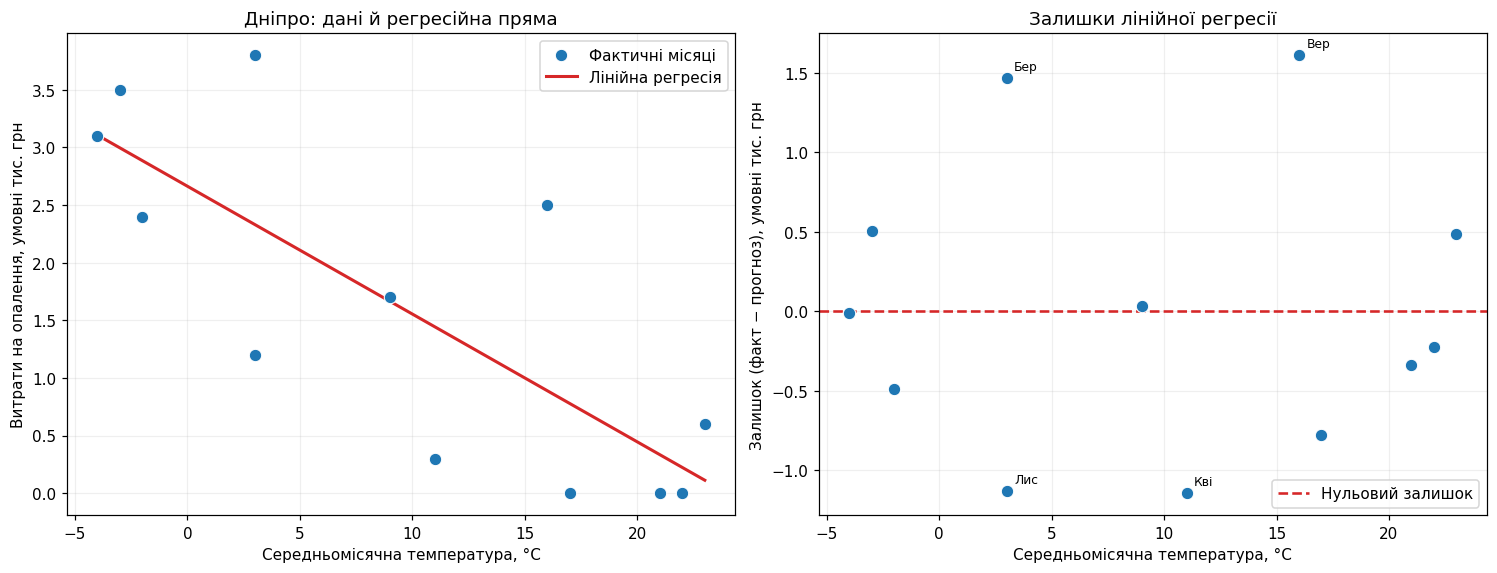

In [4]:
climate["прогноз"] = predicted
climate["залишок"] = y - predicted
print("Фактичні, розраховані значення та залишки:")
display(climate[["місяць", "температура", "витрати_на_опалення", "прогноз", "залишок"]].round(4))
print("Сума залишків (≈ 0 для моделі з вільним членом):", f"{climate['залишок'].sum():.12f}")

x_line = np.linspace(x.min(), x.max(), 250)
y_line = b0 + b1 * x_line
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.1), constrained_layout=True)
axes[0].scatter(x, y, s=66, edgecolor="white", linewidth=0.7, label="Фактичні місяці", zorder=3)
axes[0].plot(x_line, y_line, color="tab:red", lw=2, label="Лінійна регресія")
axes[0].set_xlabel("Середньомісячна температура, °C")
axes[0].set_ylabel("Витрати на опалення, умовні тис. грн")
axes[0].set_title("Дніпро: дані й регресійна пряма")
axes[0].legend()

axes[1].scatter(x, climate["залишок"], s=66, edgecolor="white", linewidth=0.7, zorder=3)
axes[1].axhline(0, color="tab:red", ls="--", lw=1.7, label="Нульовий залишок")
for i, row in climate.iterrows():
    if abs(row["залишок"]) >= 1.1:
        axes[1].annotate(row["місяць"], (row["температура"], row["залишок"]),
                         xytext=(5, 5), textcoords="offset points", fontsize=8)
axes[1].set_xlabel("Середньомісячна температура, °C")
axes[1].set_ylabel("Залишок (факт − прогноз), умовні тис. грн")
axes[1].set_title("Залишки лінійної регресії")
axes[1].legend()
plt.show()

**Аналіз конкретного графіка залишків.** Залишки є по обидва боки від нуля; явного безперервного зростання або спадання в усьому температурному діапазоні немає. Проте є помітний розкид: **вересень** ($X=16$ °C) має великий додатний залишок **+1,611**, **березень** ($X=3$ °C) — **+1,469** умовних тис. грн. Негативні залишки помітні у **квітні** ($-1,144$) та **листопаді** ($-1,131$). Це означає, що окремі місяці модель передбачає неточно, хоча $R^2$ досить помітний.

**Роль нижнього обмеження нулем.** У **травні, червні та серпні** (17, 21 і 22 °C) фактичні витрати дорівнюють **0**, але регресійна пряма передбачає приблизно **0,778; 0,335; 0,224** умовних тис. грн відповідно, тому залишки від'ємні. **Липень** (23 °C) є винятком: додатний шум дав 0,6 і відповідно додатний залишок. Через `max(cost, 0)` витрати не можуть стати від'ємними, а необмежена лінійна формула за температур **приблизно вище 24,0 °C** прогнозувала б від'ємні значення. Це свідчить про **потенційну нелінійність / ефект порогу**, яку одне число $R^2$ не показує. За всього 12 точок не слід робити сильний висновок про форму реальної залежності.

## Завдання 4. Прогноз для −10 °C і екстраполяція

Підставляємо $X=-10$ °C у рівняння та перевіряємо його положення відносно реально використаного діапазону температур.

In [5]:
new_temp = -10.0
new_prediction = b0 + b1 * new_temp
min_temp, max_temp = x.min(), x.max()
is_extrapolation = not (min_temp <= new_temp <= max_temp)
zero_crossing = -b0 / b1

print(f"Прогноз при {new_temp:g} °C: {new_prediction:.4f} умовних тис. грн")
print(f"Спостережені температури: від {min_temp:g} °C до {max_temp:g} °C")
print("Тип прогнозу:", "екстраполяція" if is_extrapolation else "інтерполяція")
print(f"За приблизно {zero_crossing:.2f} °C лінійний прогноз досягає нуля")
assert is_extrapolation

Прогноз при -10 °C: 3.7725 умовних тис. грн
Спостережені температури: від -4 °C до 23 °C
Тип прогнозу: екстраполяція
За приблизно 24.02 °C лінійний прогноз досягає нуля


**Висновок.** Для **−10 °C** модель прогнозує близько **3,772 умовних тис. грн**. Це **екстраполяція**, оскільки найхолодніше фактичне значення у вибірці — лише **−4 °C**, найтепліше — **23 °C**. За межами спостереженого діапазону ми не перевіряли, чи зберігаються той самий нахил, тарифи, кількість опалювальних днів та інші умови. Зокрема, генерація **обмежує кількість опалювальних днів 30**, чого необмежена регресійна пряма не враховує. Тому прогноз за −10 °C має нижчу надійність, ніж прогноз усередині [−4; 23] °C, і не повинен сприйматися як гарантований платіж.

## Завдання 5. Порівняння з кореляцією Пірсона з Практики 16

У **простій** лінійній регресії з вільним членом двобічна гіпотеза $H_0\colon b_1=0$ еквівалентна $H_0\colon\rho=0$, де $\rho$ — генеральний коефіцієнт кореляції Пірсона (за стандартних умов відповідного тесту). Перевіримо p-value обох функцій на одних і тих самих початкових 12 спостереженнях.

In [6]:
p_compare = pd.DataFrame({
    "Тест": ["linregress(): H₀ — нахил = 0", "pearsonr(): H₀ — кореляція = 0"],
    "Статистика": [result.slope, pearson_result.statistic],
    "p-value": [result.pvalue, pearson_result.pvalue],
})
display(p_compare.round(8))
print("Абсолютна різниця p-value:", abs(result.pvalue - pearson_result.pvalue))
print("Висновок за α=0,05:", "відхиляємо H₀" if result.pvalue < 0.05 else "не відхиляємо H₀")
assert np.isclose(result.pvalue, pearson_result.pvalue, atol=1e-13)

,Тест,Статистика,p-value
0,linregress(): H₀ — нахил = 0,-0.110888,0.002688
1,pearsonr(): H₀ — кореляція = 0,-0.781396,0.002688


Абсолютна різниця p-value: 7.806255641895632e-18
Висновок за α=0,05: відхиляємо H₀


**Пояснення.** Обидва двобічні p-value дорівнюють **приблизно 0,002688**. Для однієї пояснювальної змінної статистика перевірки ненульового нахилу пов'язана з кореляцією через $t=r\sqrt{(n-2)/(1-r^2)}$ і має ті самі $n-2$ ступені вільності. Отже, обидва тести перевіряють еквівалентні нульові гіпотези й дають однаковий висновок: **нахил статистично відмінний від нуля, а лінійна кореляція значуща** за $\alpha=0{,}05$. Цей тест сам по собі не доводить реальну причинність чи практичну придатність моделі.

## Відповіді на контрольні питання

**1. Чому метод найменших квадратів мінімізує суму квадратів залишків, а не суму самих залишків чи їхніх модулів?**  
Звичайна сума залишків може взаємно компенсувати додатні та від'ємні помилки; більше того, у регресії з вільним членом вона зазвичай дорівнює нулю. Квадрати роблять всі внески невід'ємними, сильніше штрафують великі помилки й дають гладку функцію, для якої можна отримати зручне аналітичне рішення. Сума **модулів** також придатна як альтернативний критерій (регресія найменших абсолютних відхилень), але вона оптимізує іншу ціль, менш чутлива до викидів і не має тієї самої гладкої квадратичної форми.

**2. Що змістовно означає нахил $b_1$, і чим він відрізняється від кореляції $r$?**  
Для Дніпра $b_1\approx-0{,}111$ **умовних тис. грн на 1 °C**: кожен додатковий градус температури пов'язаний у моделі зі зниженням передбачених витрат на приблизно 111 умовних грн. Нахил має **одиниці вимірювання і масштаб ефекту**; коефіцієнт кореляції $r\approx-0{,}781$ **безрозмірний**, лежить від −1 до +1 і показує напрямок та силу лінійного зв'язку, а не кількість гривень на градус.

**3. Чому високого $R^2$ недостатньо для висновку про адекватність моделі?**  
Навіть якщо модель пояснює значну частину розкиду, залишки можуть мати вигин, систематичний тренд, нерівномірну дисперсію або окремі викиди. У нашому наборі при $R^2\approx0{,}611$ особливо помітні великі залишки березня й вересня та **скупчення нульових витрат у теплі місяці**, де пряма може завищувати витрати через наявність нижньої межі 0. Тому графік залишків показує недоліки моделі, яких одне $R^2$ не розкриває.

**4. Що відбувається з надійністю прогнозу поза спостереженим діапазоном?**  
Поза діапазоном [−4; 23] °C модель робить **екстраполяцію**; її точність стає менш передбачуваною, оскільки закономірність не перевірена на таких температурах. Для −10 °C прогноз становить близько **3,772 умовних тис. грн**, але його слід трактувати обережніше, ніж прогноз усередині наявних даних, особливо через обмеження кількості опалювальних днів та інші нелінійні ефекти генерації.

## Загальний висновок

Для **варіанта №5 (Дніпро)** побудовано просту лінійну регресію **витрат на опалення від температури** на тому самому наборі, що й у Практиці 16. Отримано $\widehat{Y}=2{,}664-0{,}111X$, $R^2\approx0{,}6106$ і $p\approx0{,}002688$. Рівність $R^2=r^2$ перевірено двома розрахунками та кореляцією Пірсона. Графік залишків показав помітні помилки окремих місяців і можливий ефект нижнього обмеження витрат нулем. Прогноз для −10 °C визнано екстраполяцією, а p-value регресії узгоджено з Практикою 16. **Модель є навчальним описом синтетичних даних, а не валідованим прогнозом реальних рахунків за опалення.**